# Netflix Content Explorer

## 1. Project Title

**Netflix Content Explorer**
Minor Project — Artificial Intelligence / Data Science

A menu-driven Python application that loads the Netflix Titles Dataset, cleans it,
and answers ten business questions about the catalogue: what dominates the
library, who produces it, which genres and ratings are most common, how the
content grew over time, and how the release years are distributed.

## 2. Project Objective

The aim of this project is to demonstrate the **full data-analysis workflow** on a
real-world dataset:

1. **Load** a CSV file into a Pandas `DataFrame`.
2. **Explore** the raw data — shape, dtypes, head/tail, missing values.
3. **Clean** it — fill missing text fields, drop unusable rows, convert types.
4. **Engineer features** — derive `year_added` and split multi-value cells.
5. **Analyse** it — answer ten business questions with Pandas and NumPy.
6. **Present** the results through a console menu, like a small tool a
   content strategist could actually use.

Everything runs in a single Jupyter Notebook made of small, commented cells, so
each step can be read, understood and re-run independently.

> **Scope note:** this is deliberately a *notebook + Pandas* project. There is no
> web framework, no database, no API and no authentication. The only third-party
> libraries are Pandas, NumPy and Jupyter.

## 3. Dataset Information

| Item | Value |
| --- | --- |
| Dataset name | Netflix Movies and TV Shows (Netflix Titles) |
| Source | Kaggle — [shivamb/netflixshows](https://www.kaggle.com/datasets/shivamb/netflixshows) |
| File name | `netflix_titles.csv` |
| Location in project | `data/netflix_titles.csv` |
| Size | 8,807 rows × 12 columns |
| Row meaning | one Netflix title (a Movie or a TV Show) |

### Columns

| # | Column | Description |
| --- | --- | --- |
| 1 | `show_id` | Unique identifier for the title |
| 2 | `type` | `Movie` or `TV Show` |
| 3 | `title` | Title name |
| 4 | `director` | Director name |
| 5 | `cast` | Main cast members |
| 6 | `country` | Country of production — **may contain several comma-separated countries** |
| 7 | `date_added` | Date the title was added to Netflix |
| 8 | `release_year` | Original release year of the work |
| 9 | `rating` | Content rating (`TV-MA`, `PG-13`, …) |
| 10 | `duration` | Length, e.g. `90 min` or `3 Seasons` |
| 11 | `listed_in` | Genres — **contains several comma-separated genres** |
| 12 | `description` | Short synopsis |

### Before you run this notebook

Download `netflix_titles.csv` from Kaggle
(<https://www.kaggle.com/datasets/shivamb/netflixshows>) and place it in `data/`:

```
Netflix_Content_Explorer/
├── data/
│   └── netflix_titles.csv     <-- put the file here
└── notebooks/
    └── netflix_analysis.ipynb  <-- this notebook
```

The next cell prints clear, step-by-step instructions if the file is missing.
The original CSV is never modified — all cleaning happens on an in-memory copy.

## 4. Import Libraries

Only four imports are needed: two for data analysis (Pandas, NumPy) and three
standard-library modules used to locate the dataset and to capture a
reproducible sample run of the menu.

In [1]:
# --- Standard library -------------------------------------------------------
import io
import os
import unittest
from contextlib import redirect_stdout
from pathlib import Path
from unittest.mock import patch

# --- Data analysis and plotting (the third-party libraries used) -----------
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# Wider tables are much easier to read in the notebook and in the console.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 55)

print("Python version     :", os.sys.version.split()[0])
print("Pandas version     :", pd.__version__)
print("NumPy version      :", np.__version__)
print("Matplotlib version :", matplotlib.__version__)

Python version     : 3.10.11
Pandas version     : 2.3.3
NumPy version      : 2.2.6
Matplotlib version : 3.10.9


## 5. Load Dataset

A notebook does not have a fixed working folder: Jupyter may be started from the
project root **or** from inside `notebooks/`, so the hard-coded path
`../data/netflix_titles.csv` fails in one of those two cases.

`find_dataset()` therefore searches a few sensible candidates — including every
parent folder that contains a `data/` sub-folder — and returns the first hit.
If nothing matches, `load_dataset()` raises a `FileNotFoundError` that explains
exactly how to fix the problem instead of failing with a raw traceback.

In [2]:
DATASET_FILENAME = "netflix_titles.csv"


def find_project_root():
    """Return the project root: the folder that holds both data/ and notebooks/.

    Jupyter can be started from the project root or from inside notebooks/, so
    the root is searched for instead of hard-coding a machine-specific path.
    """
    here = Path.cwd().resolve()
    for folder in [here, *here.parents]:
        if (folder / "data").is_dir() and (folder / "notebooks").is_dir():
            return folder
    # Fallback: treat the parent of the current folder as the root.
    return here.parent


def find_dataset(filename=DATASET_FILENAME):
    """Return the path of the dataset, or None when it cannot be found.

    Candidates are checked in this order:
      1. the current working folder
      2. its parent (the usual "notebook sits in notebooks/" case)
      3. <ancestor>/data/<filename>  for every ancestor folder
      4. <ancestor>/<filename>      for every ancestor folder

    Returns:
        pathlib.Path | None: the first existing file, otherwise None.
    """
    here = Path.cwd().resolve()
    candidates = [here / filename, here.parent / filename]
    candidates += [parent / "data" / filename for parent in here.parents]
    candidates += [parent / filename for parent in here.parents]

    for candidate in candidates:
        if candidate.is_file():
            return candidate
    return None


def load_dataset(filename=DATASET_FILENAME, path=None):
    """Load the Netflix dataset into a DataFrame.

    Args:
        filename (str): name of the CSV file.
        path (Path | None): already-resolved location; found automatically
            when not supplied.

    Raises:
        FileNotFoundError: if the CSV is missing, with instructions on where
            to put it. Raising deliberately stops the notebook here instead of
            letting every later cell fail with confusing KeyError messages.
    """
    path = path or find_dataset(filename)
    if path is None:
        raise FileNotFoundError(
            f"Could not find '{filename}'.\n"
            f"Expected location: <project root>/data/{filename}\n\n"
            "How to fix it:\n"
            "  1. Download the Netflix Titles dataset (netflix_titles.csv) from Kaggle:\n"
            "     https://www.kaggle.com/datasets/shivamb/netflixshows\n"
            "  2. Make sure a 'data' folder exists next to the 'notebooks' folder.\n"
            "  3. Copy netflix_titles.csv into that 'data' folder.\n"
            "  4. Re-run this cell (Kernel > Restart and Run All)."
        )
    frame = pd.read_csv(path)
    try:
        shown_path = path.relative_to(PROJECT_ROOT)
    except ValueError:
        shown_path = path
    print(f"Dataset loaded from : {shown_path}")
    print(f"Rows read           : {len(frame):,}")
    print(f"Columns read        : {len(frame.columns)}")
    return frame


# PROJECT_ROOT and DATASET_PATH are recorded once and reused by later cells
# (for example when the sample output is saved).
PROJECT_ROOT = find_project_root()
DATASET_PATH = find_dataset(DATASET_FILENAME)

# df_raw always holds the untouched data; cleaning works on a copy called `df`,
# so the original values stay available for comparison.
df_raw = load_dataset(DATASET_FILENAME, path=DATASET_PATH)

Dataset loaded from : data\netflix_titles.csv
Rows read           : 8,807
Columns read        : 12


## 6. Initial Dataset Exploration

Before cleaning anything we look at the data to find out **what we are dealing
with**: what the rows look like, how big the table is, what type each column
has, and — most importantly — where the gaps are.

In [3]:
print("=" * 70)
print("FIRST 5 ROWS")
print("=" * 70)
display(df_raw.head())

print("\n" + "=" * 70)
print("LAST 5 ROWS")
print("=" * 70)
display(df_raw.tail())

FIRST 5 ROWS


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmmaker ..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thabang Mol...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town teen s..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Ak...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Action &...","To protect his family from a powerful drug lord, sk..."
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down among th..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam Khan, ...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV Comedies",In a city of coaching centers known to train India’...



LAST 5 ROWS


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey Jr., A...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a pair..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young girl b..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, Abiga...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zombies...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Mara, R...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero must..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanana, Ma...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a tycoon'...


In [4]:
print("Shape (rows, columns) :", df_raw.shape)

print("\nColumn names :")
for index, name in enumerate(df_raw.columns, start=1):
    print(f"  {index:>2}. {name}")

print("\nData types :")
display(df_raw.dtypes)

Shape (rows, columns) : (8807, 12)

Column names :
   1. show_id
   2. type
   3. title
   4. director
   5. cast
   6. country
   7. date_added
   8. release_year
   9. rating
  10. duration
  11. listed_in
  12. description

Data types :


show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object

In [5]:
missing = df_raw.isna().sum().sort_values(ascending=False)
missing_frame = missing.rename("missing_values").to_frame()
missing_frame["percent_of_rows"] = (missing / len(df_raw) * 100).round(2)

print("Missing values per column (raw data)")
print("=" * 70)
display(missing_frame)

print(f"\nTotal missing cells : {int(df_raw.isna().sum().sum()):,}")
print(f"Total rows          : {len(df_raw):,}")

Missing values per column (raw data)


,missing_values,percent_of_rows
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00



Total missing cells : 4,307
Total rows          : 8,807


In [6]:
print("Duplicate records (raw data)")
print("=" * 70)
print(f"Fully duplicated rows : {int(df_raw.duplicated().sum()):,}")
print(f"Duplicated show_id    : {int(df_raw['show_id'].duplicated().sum()):,}")
print(f"Duplicated title      : {int(df_raw['title'].duplicated().sum()):,}")
print("No rows are removed for duplicates because show_id is unique.")

Duplicate records (raw data)
Fully duplicated rows : 0
Duplicated show_id    : 0
Duplicated title      : 0
No rows are removed for duplicates because show_id is unique.


In [7]:
print("df_raw.info()")
print("=" * 70)
df_raw.info()

df_raw.info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


## 7. Data Cleaning

Six operations are applied, each one for a specific reason:

| # | Operation | Why |
| --- | --- | --- |
| A | Missing `country` → `"Unknown"` | Keeps the row usable for country analysis without inventing a country |
| B | Missing `director` → `"Not Listed"` | Same idea; makes "no director listed" explicit and greppable |
| C | Missing `cast` → `"Not Listed"` | Same idea for the cast column |
| D | Missing `rating` → `"Not Rated"` | The rating distribution then shows the true count, including unrated titles |
| E | Parse `date_added` safely | Turns text into real dates; unreadable values become `NaT` |
| F | Create `year_added` from `date_added` | Turns a date into a number that can be counted per year |

**Why fill instead of drop for A–D?** Those four columns are descriptive text.
Deleting thousands of otherwise valid titles would distort every count in the
project, so the missing value is replaced with an explicit placeholder.

**Two views instead of one.** Only 10 rows have a missing `date_added`. They are
kept in the **general** cleaned dataset (`df`) because a title without a date can
still answer questions about type, country, genre, rating and release year. A
separate **date-valid** view (`df_dated`) is used only by the two date-based
options (2 and 8).

Cleaning is applied to a `copy` of the data, so the CSV file and `df_raw` are
never changed.

In [8]:
rows_before = len(df_raw)
cells_before = int(df_raw.isna().sum().sum())

# Missing descriptive text is filled with a visible, greppable placeholder.
# Missing dates are handled separately, because they drive the time-based options.
FILL_VALUES = {
    "country": "Unknown",
    "director": "Not Listed",
    "cast": "Not Listed",
    "rating": "Not Rated",
}


def to_datetime_safe(series):
    """Convert a column to datetime, tolerating inconsistent string layouts.

    Args:
        series (pd.Series): the raw column, usually dtype object.

    Returns:
        pd.Series: datetime64 values, with unreadable entries as NaT.
    """
    try:
        return pd.to_datetime(series, errors="coerce", format="mixed")
    except (ValueError, TypeError):
        # Extremely defensive fallback for pandas builds without "mixed".
        return pd.to_datetime(series, errors="coerce")


def clean_dataframe(raw):
    """Apply every cleaning rule to a copy of the raw data.

    Fills the descriptive text columns, parses `date_added` into real datetimes
    and derives `year_added`. Rows are NOT removed here: a title without a date
    is still valid for every analysis that does not need a date.

    Args:
        raw (pd.DataFrame): the untouched data straight from the CSV.

    Returns:
        tuple(pd.DataFrame, dict): the cleaned data plus a dictionary of counts
        describing what the cleaning did (used by the summary and the tests).
    """
    clean = raw.copy()
    details = {"rows_in": len(clean), "filled": {}}

    for column, placeholder in FILL_VALUES.items():
        details["filled"][column] = int(clean[column].isna().sum())
        clean[column] = clean[column].fillna(placeholder)

    parsed = to_datetime_safe(clean["date_added"])
    details["unparsed_dates"] = int(parsed.isna().sum())
    clean["date_added"] = parsed
    # Nullable Int32 keeps whole years while still allowing a missing value.
    clean["year_added"] = parsed.dt.year.astype("Int32")
    return clean, details


# df is the GENERAL cleaned dataset: every raw row is kept.
df, clean_details = clean_dataframe(df_raw)

print(f"Rows before cleaning : {rows_before:,}")
print(f"Missing cells before : {cells_before:,}")
df.head(3)

Rows before cleaning : 8,807
Missing cells before : 4,307


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Not Listed,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmmaker ...",2021
1,s2,TV Show,Blood & Water,Not Listed,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thabang Mol...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town teen s...",2021
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Ak...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Action &...","To protect his family from a powerful drug lord, sk...",2021


### 7.1  A–D — Fill missing text values with explicit placeholders

In [9]:
print("Missing text values filled with a visible placeholder")
print("-" * 70)
for column, placeholder in FILL_VALUES.items():
    print(f"{column:<10} : filled {clean_details['filled'][column]:>5} "
          f"missing value(s) with '{placeholder}'")

print(f"\ndate_added parsed        : "
      f"{len(df) - clean_details['unparsed_dates']:,} value(s) readable")
print(f"date_added not parseable : {clean_details['unparsed_dates']:,} value(s)")

Missing text values filled with a visible placeholder
----------------------------------------------------------------------
country    : filled   831 missing value(s) with 'Unknown'
director   : filled  2634 missing value(s) with 'Not Listed'
cast       : filled   825 missing value(s) with 'Not Listed'
rating     : filled     4 missing value(s) with 'Not Rated'

date_added parsed        : 8,797 value(s) readable
date_added not parseable : 10 value(s)


### 7.2  E — Parse `date_added` and keep a separate date-valid view

`pd.to_datetime(..., errors="coerce")` turns anything it cannot read into
`NaT` instead of raising, so a stray text cell cannot stop the notebook.

`format="mixed"` tells Pandas to infer the layout of *each* value separately,
which matters because the dataset stores `date_added` either as ISO text
(`2017-09-01`) or as free English text (`September 1, 2017`).

Only 10 rows are missing a `date_added`, and they are **not dropped from the
general dataset**: a title without a date can still answer questions about
content type, country, genre, rating and release year. The notebook therefore
keeps two views:

* `df` — the general cleaned data (all rows), used by options 1, 3, 4, 5, 6, 7, 9 and 10.
* `df_dated` — the date-valid view, used only by the date-based options 2 and 8.

In [10]:
print("date_added sample values (parsed):")
display(df["date_added"].dropna().head(5).to_frame())

unreadable = int(df["date_added"].isna().sum())
print(f"\nRows with a missing or unreadable date_added : {unreadable:,}")
print(f"Rows kept in the general dataset             : {len(df):,}")

# The date-based options (2 and 8) need a real date, so they use this smaller
# view. Every other option keeps the full, general dataset.
df_dated = df.loc[df["date_added"].notna()].reset_index(drop=True).copy()
print(f"Rows kept in the date-valid dataset          : {len(df_dated):,}")

date_added sample values (parsed):


,date_added
0,2021-09-25
1,2021-09-24
2,2021-09-24
3,2021-09-24
4,2021-09-24



Rows with a missing or unreadable date_added : 10
Rows kept in the general dataset             : 8,807
Rows kept in the date-valid dataset          : 8,797


### 7.3  F — Create `year_added` from the cleaned `date_added`

`year_added` is derived for the whole dataset, but it is only populated where a
date exists, so the date-based options read it from the date-valid view.

In [11]:
print("date_added dtype :", df["date_added"].dtype)
print("year_added dtype :", df["year_added"].dtype)
display(df[["title", "date_added", "year_added"]].head())

date_added dtype : datetime64[ns]
year_added dtype : Int32


,title,date_added,year_added
0,Dick Johnson Is Dead,2021-09-25,2021
1,Blood & Water,2021-09-24,2021
2,Ganglands,2021-09-24,2021
3,Jailbirds New Orleans,2021-09-24,2021
4,Kota Factory,2021-09-24,2021


### 7.4  Cleaning summary

Row counts, remaining missing values and the validation checks required by the
brief. Every check prints `PASS` or `FAIL` — nothing is hidden or swallowed.

In [12]:
rows_after = len(df)
rows_dated = len(df_dated)

print("=" * 70)
print("CLEANING SUMMARY")
print("=" * 70)
print(f"Raw rows                        : {rows_before:,}")
print(f"Rows dropped (missing date)     : {rows_before - rows_dated:,}  "
      "(excluded only from options 2 and 8)")
print(f"General cleaned rows            : {rows_after:,}")
print(f"Date-valid rows (options 2, 8)  : {rows_dated:,}")
print(f"Missing cells before cleaning   : {cells_before:,}")

print("\nRemaining missing values per column (general dataset)")
print("-" * 70)
remaining = df.isna().sum()
still_missing = remaining[remaining > 0]
if still_missing.empty:
    print("No missing values left in the cleaned data.")
else:
    display(still_missing.rename("missing_values").to_frame())
    print("Note: date_added and year_added are intentionally left empty for the")
    print("10 rows without a date, so their titles stay available to the other")
    print("analyses. duration is not covered by the cleaning rules of the brief,")
    print("so its values are reported as they are rather than filled.")

CLEANING SUMMARY
Raw rows                        : 8,807
Rows dropped (missing date)     : 10  (excluded only from options 2 and 8)
General cleaned rows            : 8,807
Date-valid rows (options 2, 8)  : 8,797
Missing cells before cleaning   : 4,307

Remaining missing values per column (general dataset)
----------------------------------------------------------------------


,missing_values
date_added,10
duration,3
year_added,10


Note: date_added and year_added are intentionally left empty for the
10 rows without a date, so their titles stay available to the other
analyses. duration is not covered by the cleaning rules of the brief,
so its values are reported as they are rather than filled.


In [13]:
checks = {
    "date_added was converted to datetime":
        str(df["date_added"].dtype).startswith("datetime64"),
    "general dataset keeps every raw row":
        len(df) == len(df_raw),
    "date-valid dataset has no missing date_added":
        df_dated["date_added"].isna().sum() == 0,
    "year_added was created":
        "year_added" in df.columns,
    "year_added has no missing values in the date-valid dataset":
        df_dated["year_added"].notna().all(),
    "country missing values replaced with 'Unknown'":
        (df["country"] == "Unknown").any() and df["country"].isna().sum() == 0,
    "director missing values replaced with 'Not Listed'":
        (df["director"] == "Not Listed").any() and df["director"].isna().sum() == 0,
    "cast missing values replaced with 'Not Listed'":
        (df["cast"] == "Not Listed").any() and df["cast"].isna().sum() == 0,
    "rating missing values replaced with 'Not Rated'":
        (df["rating"] == "Not Rated").any() and df["rating"].isna().sum() == 0,
    "one row per show_id (no duplicates introduced)":
        df["show_id"].is_unique,
}

print("DATA VALIDATION")
print("=" * 70)
for description, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {description}")

failed = [name for name, passed in checks.items() if not passed]
print("\nAll checks passed." if not failed else f"\nChecks to investigate: {failed}")

DATA VALIDATION
[PASS] date_added was converted to datetime
[PASS] general dataset keeps every raw row
[PASS] date-valid dataset has no missing date_added
[PASS] year_added was created
[PASS] year_added has no missing values in the date-valid dataset
[PASS] country missing values replaced with 'Unknown'
[PASS] director missing values replaced with 'Not Listed'
[PASS] cast missing values replaced with 'Not Listed'
[PASS] rating missing values replaced with 'Not Rated'
[PASS] one row per show_id (no duplicates introduced)

All checks passed.


In [14]:
print("df.info() after cleaning (general dataset)")
print("=" * 70)
df.info()

df.info() after cleaning (general dataset)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8807 non-null   object        
 1   type          8807 non-null   object        
 2   title         8807 non-null   object        
 3   director      8807 non-null   object        
 4   cast          8807 non-null   object        
 5   country       8807 non-null   object        
 6   date_added    8797 non-null   datetime64[ns]
 7   release_year  8807 non-null   int64         
 8   rating        8807 non-null   object        
 9   duration      8804 non-null   object        
 10  listed_in     8807 non-null   object        
 11  description   8807 non-null   object        
 12  year_added    8797 non-null   Int32         
dtypes: Int32(1), datetime64[ns](1), int64(1), object(10)
memory usage: 868.8+ KB


## 8. Feature Engineering

Cleaning makes the data *valid*; feature engineering makes it *useful*. Three
new things are derived here.

### 8.1 Why multi-value cells must be split

`country` and `listed_in` hold **lists inside a single cell**:

```
country    : "United States, Canada"
listed_in  : "Dramas, International Movies"
```

Counting the cell as one value is wrong. A naive
`df["country"].value_counts()` would report one "United States, Canada" row
and hide both real countries, and a single title listed in five genres would
count as one genre instead of five.

The fix is to **explode** those cells: each comma-separated value becomes its
own row, and the analysis is done on that exploded table. After splitting, one
title can legitimately count once for every country it was produced in and once
for every genre it belongs to — which is exactly what a business user expects
from "number of titles per country".

In [15]:
# release_year is numeric data, but a bad cell would make Pandas read the whole
# column as text. Coercing to numeric first turns any bad value into NaN so the
# NumPy statistics in option 10 cannot break. Int64 ("nullable integer") is used
# instead of float so the tables print 2019 and not 2019.0, while still being
# able to hold a missing value.
raw_years = pd.to_numeric(df["release_year"], errors="coerce")
invalid_years = int(raw_years.isna().sum())
df["release_year"] = raw_years.astype("Int64")
print(f"release_year values that were missing or invalid : {invalid_years:,}")

# 2016 -> 2010, 1994 -> 1990. Useful for a "which era dominates?" question.
df["release_decade"] = (df["release_year"] // 10 * 10).astype("Int64")

# duration looks like "90 min" or "3 Seasons"; keep only the leading number.
df["duration_minutes"] = df["duration"].str.extract(r"(\d+)", expand=False).astype("float")


def explode_multi_value(frame, column):
    """Turn a comma-separated column into one row per value.

    Args:
        frame (pd.DataFrame): the cleaned catalogue.
        column (str): column holding comma-separated values.

    Returns:
        pd.DataFrame: one row per (title, value) pair, blanks removed.
    """
    exploded = (
        frame[["show_id", "title", column]]
        .assign(**{column: frame[column].astype("string").str.split(",")})
        .explode(column)
    )
    # Trailing spaces after a comma ("Canada, India") would otherwise create
    # duplicate-looking categories.
    exploded[column] = exploded[column].str.strip()
    exploded = exploded[exploded[column].notna() & (exploded[column] != "")]
    return exploded.reset_index(drop=True)


# Long-format tables used by options 3, 4 and 9. Built from the general dataset,
# so no title is lost because of a missing date.
country_rows = explode_multi_value(df, "country")
genre_rows = explode_multi_value(df, "listed_in")

print("Original rows                :", len(df))
print("Rows after splitting country:", len(country_rows))
print("Rows after splitting genres :", len(genre_rows))
print("\nExample: one country cell expanded")
print("-" * 70)
country_rows.head(8)

release_year values that were missing or invalid : 0
Original rows                : 8807
Rows after splitting country: 10843
Rows after splitting genres : 19323

Example: one country cell expanded
----------------------------------------------------------------------


,show_id,title,country
0,s1,Dick Johnson Is Dead,United States
1,s2,Blood & Water,South Africa
2,s3,Ganglands,Unknown
3,s4,Jailbirds New Orleans,Unknown
4,s5,Kota Factory,India
5,s6,Midnight Mass,Unknown
6,s7,My Little Pony: A New Generation,Unknown
7,s8,Sankofa,United States


In [16]:
print("Example: one genre cell expanded")
print("-" * 70)
display(genre_rows.head(8))

print("\nNew columns created by feature engineering")
print("-" * 70)
display(df[["title", "release_year", "release_decade", "duration", "duration_minutes"]].head())

Example: one genre cell expanded
----------------------------------------------------------------------


,show_id,title,listed_in
0,s1,Dick Johnson Is Dead,Documentaries
1,s2,Blood & Water,International TV Shows
2,s2,Blood & Water,TV Dramas
3,s2,Blood & Water,TV Mysteries
4,s3,Ganglands,Crime TV Shows
5,s3,Ganglands,International TV Shows
6,s3,Ganglands,TV Action & Adventure
7,s4,Jailbirds New Orleans,Docuseries



New columns created by feature engineering
----------------------------------------------------------------------


,title,release_year,release_decade,duration,duration_minutes
0,Dick Johnson Is Dead,2020,2020,90 min,90.0
1,Blood & Water,2021,2020,2 Seasons,2.0
2,Ganglands,2021,2020,1 Season,1.0
3,Jailbirds New Orleans,2021,2020,1 Season,1.0
4,Kota Factory,2021,2020,2 Seasons,2.0


,title,release_year,release_decade,duration,duration_minutes
0,Dick Johnson Is Dead,2020,2020,90 min,90.0
1,Blood & Water,2021,2020,2 Seasons,2.0
2,Ganglands,2021,2020,1 Season,1.0
3,Jailbirds New Orleans,2021,2020,1 Season,1.0
4,Kota Factory,2021,2020,2 Seasons,2.0


## 9. Analysis Functions

Each menu option is a separate function with a docstring, so options can be
tested, reused or reordered independently. Every function:

* takes an optional `frame` (or `table`) argument, so it can run on the real
  dataset **or** on a tiny sample for testing;
* returns its result as a Series / DataFrame / dict, which the tests in
  section 14 assert on;
* prints a clearly headed result using two small helpers.

`print_header(title)` draws the `=====` banner and `print_table(frame)` prints a
DataFrame without the Pandas index. `MAX_ROWS_SHOWN` caps the very long result
lists (options 7 and 8 can match hundreds of titles); the **total count is always
printed**, so nothing is hidden from the user.

In [17]:
LINE = "=" * 50
MAX_ROWS_SHOWN = 20          # rows printed for long result lists


def print_header(title):
    """Print a consistent banner above an option's result."""
    print()
    print(LINE)
    print(title.upper())
    print(LINE)


def print_table(table):
    """Print a DataFrame as a plain-text table without the Pandas index."""
    print(table.to_string(index=False))

### Option 1 — Count of Movies vs TV Shows

In [18]:
def count_movies_tvshows(frame=None):
    """Count how many Movies and how many TV Shows are in the catalogue.

    Args:
        frame (pd.DataFrame | None): data to analyse. Defaults to the general
            cleaned dataset `df`, but any DataFrame can be passed in, which
            makes the function easy to test with small sample data.

    Returns:
        pd.DataFrame: one row per content type, with its count and percentage.
    """
    frame = df if frame is None else frame
    print_header("Movies vs TV Shows")

    counts = frame["type"].value_counts(dropna=False)
    total = int(counts.sum())

    if total == 0:
        print("No content types available.")
        return pd.DataFrame(columns=["Content Type", "Count", "Percentage"])

    table = pd.DataFrame({
        "Content Type": counts.index,
        "Count": counts.values,
    })
    table["Percentage"] = (table["Count"] / total * 100).map("{:.2f}%".format)

    print_table(table)
    print(f"\nTotal titles: {total:,}")
    top_type, top_count = counts.index[0], int(counts.iloc[0])
    print(f"Most common type: {top_type} ({top_count:,} titles, "
          f"{top_count / total * 100:.2f}%)")
    return table

### Option 2 — Number of Titles Added Each Year

In [19]:
def titles_added_each_year(frame=None):
    """Count the titles Netflix added in each calendar year.

    Uses the date-valid dataset `df_dated` by default, because `year_added` is
    only meaningful for rows that have a usable `date_added`.

    Args:
        frame (pd.DataFrame | None): defaults to `df_dated`.

    Returns:
        pd.Series: counts indexed by year_added, in chronological order.
    """
    frame = df_dated if frame is None else frame
    print_header("Titles Added Each Year")

    per_year = frame["year_added"].value_counts().sort_index()

    if per_year.empty:
        print("No year_added values available.")
        return per_year

    table = pd.DataFrame({
        "Year Added": [int(year) for year in per_year.index],
        "Number of Titles": per_year.values,
    })
    print_table(table)

    print(f"\nTotal titles added : {int(per_year.sum()):,}")
    print(f"Years covered      : {int(per_year.index.min())} - {int(per_year.index.max())}")
    print(f"Number of years    : {len(per_year)}")
    return per_year

### Option 3 — Top 10 Producing Countries

In [20]:
def top_countries(n=10, table=None):
    """Rank countries by number of titles.

    Reads the exploded `country_rows` table, so a title co-produced by several
    countries contributes to each of them instead of being hidden inside a
    long comma-separated string.

    Args:
        n (int): how many countries to show.
        table (pd.DataFrame | None): defaults to `country_rows`.

    Returns:
        pd.Series: the top-n country counts.
    """
    table = country_rows if table is None else table
    print_header(f"Top {n} Producing Countries")

    counts = table["country"].value_counts().head(n)

    if counts.empty:
        print("No country values available.")
        return counts

    result = pd.DataFrame({
        "Rank": range(1, len(counts) + 1),
        "Country": counts.index,
        "Number of Titles": counts.values,
    })
    print_table(result)

    print(f"\nNote: a title produced in several countries is counted once for each")
    print(f"country, so these numbers add up to more than the {len(df):,} titles in")
    print("the catalogue. Rows with no country listed appear as 'Unknown'.")
    return counts

### Option 4 — Top 5 Most Common Genres

In [21]:
def top_genres(n=5, table=None):
    """Rank genres by number of titles using the exploded `listed_in` column.

    Args:
        n (int): how many genres to show.
        table (pd.DataFrame | None): defaults to `genre_rows`.

    Returns:
        pd.Series: the top-n genre counts.
    """
    table = genre_rows if table is None else table
    print_header(f"Top {n} Most Common Genres")

    counts = table["listed_in"].value_counts().head(n)

    if counts.empty:
        print("No genre values available.")
        return counts

    result = pd.DataFrame({
        "Rank": range(1, len(counts) + 1),
        "Genre": counts.index,
        "Number of Titles": counts.values,
    })
    print_table(result)

    print(f"\nNote: one title can belong to several genres, so the genre counts")
    print(f"add up to more than the {len(df):,} titles in the catalogue.")
    return counts

### Option 5 — Rating Distribution

In [22]:
def rating_distribution(frame=None):
    """Show every content rating and how many titles carry it.

    Rows whose rating was missing were labelled 'Not Rated' during cleaning, so
    the distribution reflects the whole catalogue instead of quietly ignoring
    unrated titles. Results are sorted from most to least common.

    Args:
        frame (pd.DataFrame | None): defaults to the general dataset `df`.

    Returns:
        pd.Series: rating counts, most common first.
    """
    frame = df if frame is None else frame
    print_header("Rating Distribution")

    counts = frame["rating"].value_counts(dropna=False)
    total = int(counts.sum())

    if total == 0:
        print("No rating values available.")
        return counts

    table = pd.DataFrame({
        "Rating": counts.index,
        "Number of Titles": counts.values,
    })
    table["Percentage"] = (table["Number of Titles"] / total * 100).map("{:.2f}%".format)

    print_table(table)
    print(f"\nDistinct ratings   : {len(table)}")
    print(f"Unrated titles     : {int((frame['rating'] == 'Not Rated').sum()):,}")
    print("Sorted by number of titles, most common first.")
    return counts

### Option 6 — Oldest and Newest Release Years

In [23]:
def release_year_range(frame=None):
    """Show the oldest and newest release year, plus the titles behind them.

    Invalid or missing release years are ignored by `dropna()`, and the empty
    check stops a confusing error when no valid year is left at all.

    Args:
        frame (pd.DataFrame | None): defaults to the general dataset `df`.

    Returns:
        dict: {"oldest": int, "newest": int, "oldest_titles": list,
        "newest_titles": list}, or an empty dict when there is no valid year.
    """
    frame = df if frame is None else frame
    print_header("Oldest and Newest Release Years")

    years = frame["release_year"].dropna()
    if years.empty:
        print("No valid release_year values found in the dataset.")
        return {}

    oldest = int(years.min())
    newest = int(years.max())

    print(f"Oldest Release Year : {oldest}")
    print(f"Newest Release Year : {newest}")
    print(f"Range (years)       : {newest - oldest}")
    print(f"Missing years       : {int(frame['release_year'].isna().sum()):,}")

    titles_by_year = {}
    for label, year in (("Oldest", oldest), ("Newest", newest)):
        titles = frame.loc[frame["release_year"] == year, "title"].dropna().unique()
        titles_by_year[label] = [str(title) for title in titles]
        preview = ", ".join(str(title) for title in titles[:5])
        if len(titles) > 5:
            preview += f", ... (+{len(titles) - 5} more)"
        print(f"\n{label} title(s) released in {year} ({len(titles)}):")
        print(f"  {preview}")

    return {
        "oldest": oldest,
        "newest": newest,
        "oldest_titles": titles_by_year["Oldest"],
        "newest_titles": titles_by_year["Newest"],
    }

### Option 7 — Search Titles by Keyword

In [24]:
def search_titles(frame=None, keyword=None):
    """Search the `title` column for a keyword, ignoring letter case.

    An empty keyword is treated as "no search requested" instead of matching
    every title, which would be a useless answer. The match is literal
    (`regex=False`), so characters such as '(', '*' or '?' are searched as plain
    text instead of being treated as a regular expression.

    Args:
        frame (pd.DataFrame | None): defaults to the general dataset `df`.
        keyword (str | None): when None the user is asked to type one.

    Returns:
        pd.DataFrame | None: the matching rows, or None for an empty keyword.
    """
    frame = df if frame is None else frame
    print_header("Search Titles by Keyword")

    keyword = input("Enter keyword: ").strip() if keyword is None else str(keyword).strip()

    if not keyword:
        print("\nNo keyword entered. Nothing to search for.")
        return None

    # na=False keeps rows with a missing title out of the result instead of
    # turning them into NaN/False rows.
    mask = frame["title"].astype("string").str.contains(
        keyword, case=False, na=False, regex=False
    )
    matches = frame.loc[mask, ["title", "type", "release_year", "rating", "listed_in"]]

    if matches.empty:
        print("\nNo titles found.")
        return matches

    matches = matches.rename(columns={
        "title": "Title",
        "type": "Type",
        "release_year": "Release Year",
        "rating": "Rating",
        "listed_in": "Genres",
    })

    print(f"\nMatching titles for '{keyword}' ({len(matches)}):")
    print("-" * 50)
    print_table(matches.head(MAX_ROWS_SHOWN))

    if len(matches) > MAX_ROWS_SHOWN:
        print(f"... and {len(matches) - MAX_ROWS_SHOWN} more matches. "
              f"Use a longer keyword, or raise MAX_ROWS_SHOWN.")
    return matches

### Option 8 — Content Added in a Specific Year

In [25]:
def ask_for_year(prompt="Enter year: "):
    """Ask the user for a year until a valid 4-digit year is typed.

    Returns:
        int | None: the validated year, or None when the user submits nothing.
            Returning None (instead of a broken string) is what keeps input
            such as "abc" from crashing the program.
    """
    latest_possible = pd.Timestamp.today().year + 1

    while True:
        raw = input(prompt).strip()

        if not raw:
            print("No year entered. Returning to the menu.")
            return None

        # isdigit() rejects "2019a", "19.9", "-2019" and empty strings in one go.
        if not raw.isdigit():
            print("Invalid year. Please type digits only, for example 2019.")
            continue

        year = int(raw)
        if not 1900 <= year <= latest_possible:
            print(f"Invalid year. Please enter a year between 1900 and {latest_possible}.")
            continue

        return year


def content_added_in_year(frame=None, year=None):
    """List the content Netflix added during a year chosen by the user.

    Args:
        frame (pd.DataFrame | None): defaults to the date-valid dataset `df_dated`.
        year (int | None): when None the user is asked to type one.

    Returns:
        pd.DataFrame | None: the titles added in that year, or None when the
            user entered no year.
    """
    frame = df_dated if frame is None else frame
    print_header("Content Added in a Specific Year")

    if year is None:
        year = ask_for_year()
    if year is None:
        return None

    subset = frame.loc[
        frame["year_added"] == year,
        ["title", "type", "release_year", "rating", "date_added"],
    ]

    if subset.empty:
        print("\nNo content found for that year.")
        if frame["year_added"].notna().any():
            print(f"Years that contain content: {int(frame['year_added'].min())} - "
                  f"{int(frame['year_added'].max())}")
        return subset

    subset = subset.rename(columns={
        "title": "Title",
        "type": "Type",
        "release_year": "Release Year",
        "rating": "Rating",
        "date_added": "Date Added",
    })

    print(f"\n{len(subset)} title(s) added in {year}:")
    print("-" * 50)
    print_table(subset.head(MAX_ROWS_SHOWN))

    if len(subset) > MAX_ROWS_SHOWN:
        print(f"... and {len(subset) - MAX_ROWS_SHOWN} more titles. "
              f"Raise MAX_ROWS_SHOWN to print all of them.")
    return subset

### Option 9 — Total Unique Countries

In [26]:
def unique_countries(table=None):
    """Count the distinct countries in the catalogue.

    `df["country"].nunique()` is deliberately NOT used for the headline number:
    the raw column contains cells such as "United States, Canada", so nunique()
    would count that pair as a single "country" and under-report badly.

    Documented rule: the headline number INCLUDES the placeholder "Unknown"
    (it is a real value after cleaning), while the real-country count EXCLUDES
    it. Both numbers are printed so the rule is transparent.

    Args:
        table (pd.DataFrame | None): defaults to `country_rows`.

    Returns:
        dict: {"total": int, "named": int}
    """
    table = country_rows if table is None else table
    print_header("Total Unique Countries")

    countries = table["country"].dropna()
    named = countries[countries != "Unknown"]

    total = int(countries.nunique())
    named_total = int(named.nunique())

    print(f"Total Unique Countries: {total}")
    print(f"Excluding 'Unknown'   : {named_total}")
    print("\nDocumented rule: 'Unknown' is included in the total because it is a")
    print("real value in the cleaned data (titles with no country listed). The")
    print("second line shows how many countries are actually named.")
    return {"total": total, "named": named_total}

### Option 10 — Summary Statistics on Release Year (NumPy)

In [27]:
def release_year_statistics(frame=None):
    """Compute summary statistics for release_year with NumPy.

    The cleaned column is converted to a NumPy array first, because the brief
    requires the numerical work to be done with NumPy rather than Pandas.

    Note on the standard deviation: np.std() defaults to ddof=0, i.e. the
    *population* standard deviation of the full catalogue. ddof=1 (the sample
    value) is reported underneath for comparison.

    Args:
        frame (pd.DataFrame | None): defaults to the general dataset `df`.

    Returns:
        dict: the computed statistics (empty when there is no valid year).
    """
    frame = df if frame is None else frame
    print_header("Summary Statistics on Release Year (NumPy)")

    years = frame["release_year"].dropna().to_numpy(dtype=float)

    if years.size == 0:
        print("No valid release_year values found in the dataset.")
        return {}

    stats = {
        "count": int(years.size),
        "mean": float(np.mean(years)),
        "median": float(np.median(years)),
        "min": int(np.min(years)),
        "max": int(np.max(years)),
        "std": float(np.std(years)),
        "std_sample": float(np.std(years, ddof=1)),
        "q1": float(np.percentile(years, 25)),
        "q3": float(np.percentile(years, 75)),
    }

    print(f"Count (valid values)  : {stats['count']:,}")
    print(f"Count (missing values): {int(frame['release_year'].isna().sum()):,}")
    print(f"Mean Release Year    : {stats['mean']:.2f}")
    print(f"Median Release Year  : {stats['median']:.0f}")
    print(f"Minimum Release Year : {stats['min']}")
    print(f"Maximum Release Year : {stats['max']}")
    print(f"Standard Deviation   : {stats['std']:.2f}")
    print(f"Std Dev (sample)     : {stats['std_sample']:.2f}")
    print(f"Q1 Release Year      : {stats['q1']:.0f}")
    print(f"Q3 Release Year      : {stats['q3']:.0f}")
    print(f"Interquartile Range  : {stats['q3'] - stats['q1']:.0f} years")
    return stats

## 10. Menu-Driven Program

`display_menu()` prints the menu, `main()` keeps showing it until the user
types `0`, and a dictionary maps each valid choice to its function.

Two robustness details matter for a console program:

* `input()` is wrapped for `EOFError` / `KeyboardInterrupt` so `Ctrl+C` and a
  closed input stream end the program politely instead of printing a traceback.
* Each option runs inside its own `try/except`, so one failing analysis cannot
  kill the whole menu session.

In [28]:
MENU = (
    "1. Count of Movies vs TV Shows",
    "2. Number of Titles Added Each Year",
    "3. Top 10 Producing Countries",
    "4. Top 5 Most Common Genres",
    "5. Rating Distribution",
    "6. Oldest and Newest Release Years",
    "7. Search Titles by Keyword",
    "8. Content Added in a Specific Year",
    "9. Total Unique Countries",
    "10. Summary Statistics on Release Year",
    "0. Quit",
)


def display_menu():
    """Print the NETFLIX CONTENT EXPLORER menu."""
    print()
    print(LINE)
    print("NETFLIX CONTENT EXPLORER")
    print(LINE)
    for option in MENU:
        print(option)
    print()

In [29]:
def main():
    """Show the menu and run the selected option until the user picks 0.

    Returns:
        None
    """
    # Mapping the menu number to a function means the if/elif chain is not
    # needed: looking the choice up in the dictionary handles both "run this"
    # and "not a valid option".
    actions = {
        "1": count_movies_tvshows,
        "2": titles_added_each_year,
        "3": top_countries,
        "4": top_genres,
        "5": rating_distribution,
        "6": release_year_range,
        "7": search_titles,
        "8": content_added_in_year,
        "9": unique_countries,
        "10": release_year_statistics,
    }

    display_menu()

    while True:
        try:
            choice = input("Enter your choice: ").strip()
        except (EOFError, KeyboardInterrupt):
            print("\nGoodbye!")
            break

        if choice == "0":
            print("\nGoodbye! Thanks for using the Netflix Content Explorer.")
            break

        action = actions.get(choice)
        if action is None:
            print("\nInvalid choice. Please enter a number from 0 to 10.")
            continue

        try:
            action()
        except Exception as error:
            # A menu should survive a single bad result: report the problem and
            # go back to the menu rather than terminating the program.
            print(f"\nSomething went wrong while running option {choice}: {error}")

### 10.1 Run the program

Uncomment the next cell to start the interactive menu. During an automated run
(or when no input is available, e.g. in a plain script) the cell is left
commented out and the sample run in section 11 is used instead.

In [30]:
# To start the interactive menu, remove the "#" from the line below and run
# this cell. Each option can be chosen as many times as needed.
#
# main()

## 11. Sample Run

The brief requires a sample run that demonstrates **every** menu option,
including real user input for the two interactive options
(option 7 = `dark`, option 8 = `2019`).

Running the menu by hand and copy-pasting the console makes the sample output
impossible to reproduce exactly, so the cell below drives `main()` with a fixed
list of keystrokes: `builtins.input` is temporarily replaced by a queue of
answers and the console output is captured. The captured text is the file
`output/sample_output.txt`.

In [31]:
def run_scripted_session(script):
    """Run the whole menu non-interactively and return the console output.

    Args:
        script (list[str]): the keystrokes a user would type, in order.

    Returns:
        str: everything main() printed, ready to be saved or displayed.
    """
    buffer = io.StringIO()
    # side_effect makes every input() call return the next scripted answer, so
    # main() runs its normal while-loop exactly as it would for a real user.
    with patch("builtins.input", side_effect=list(script)):
        with redirect_stdout(buffer):
            main()
    return buffer.getvalue()


# One pass over every option. Note the order: the menu itself asks for a
# number, and options 7 and 8 ask a *second* question of their own once they
# are running, so "dark" and "2019" must come right after "7" and "8".
SESSION_SCRIPT = ["1", "2", "3", "4", "5", "6", "7", "dark", "8", "2019", "9", "10", "0"]

session_output = run_scripted_session(SESSION_SCRIPT)
print(session_output)


NETFLIX CONTENT EXPLORER
1. Count of Movies vs TV Shows
2. Number of Titles Added Each Year
3. Top 10 Producing Countries
4. Top 5 Most Common Genres
5. Rating Distribution
6. Oldest and Newest Release Years
7. Search Titles by Keyword
8. Content Added in a Specific Year
9. Total Unique Countries
10. Summary Statistics on Release Year
0. Quit


MOVIES VS TV SHOWS
Content Type  Count Percentage
       Movie   6131     69.62%
     TV Show   2676     30.38%

Total titles: 8,807
Most common type: Movie (6,131 titles, 69.62%)

TITLES ADDED EACH YEAR
 Year Added  Number of Titles
       2008                 2
       2009                 2
       2010                 1
       2011                13
       2012                 3
       2013                11
       2014                24
       2015                82
       2016               429
       2017              1188
       2018              1649
       2019              2016
       2020              1879
       2021              149

### 11.1 Save the sample output

The cell below writes the captured run to `output/sample_output.txt`, so the
deliverable is regenerated automatically from the real dataset every time the
notebook is run.

In [32]:
OUTPUT_FILE = PROJECT_ROOT / "output" / "sample_output.txt"
OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)

# A short header makes the saved file self-documenting: it records the dataset
# and the keystrokes behind the transcript. The transcript itself is left exactly
# as the menu printed it.
header = (
    "NETFLIX CONTENT EXPLORER - SAMPLE RUN\n"
    "=======================================\n"
    f"Dataset used    : data/{DATASET_FILENAME}\n"
    f"General rows    : {len(df):,}  (used by options 1, 3, 4, 5, 6, 7, 9, 10)\n"
    f"Date-valid rows : {len(df_dated):,}  (used by options 2 and 8)\n"
    f"Rows dropped for a missing date_added: {rows_before - len(df_dated):,}\n"
    f"Keystrokes      : {', '.join(SESSION_SCRIPT)}\n"
    "                  (the menu asks for a number, then options 7 and 8 each\n"
    "                   ask one extra question - a keyword and a year)\n"
    "Covers          : menu options 1-10 and 0 (Quit)\n"
    "Reproduce with  : jupyter nbconvert --to notebook --execute --inplace \\\n"
    "                    notebooks/netflix_analysis.ipynb\n"
    "=======================================\n\n"
)
OUTPUT_FILE.write_text(header + session_output, encoding="utf-8")

try:
    shown_output = OUTPUT_FILE.relative_to(PROJECT_ROOT)
except ValueError:
    shown_output = OUTPUT_FILE
print(f"Saved sample output to: {shown_output}")
print(f"Characters written    : {len(header + session_output):,}")

Saved sample output to: output\sample_output.txt
Characters written    : 11,294


### 11.2 Error-handling demonstration

The same trick can show that the program survives bad input: a menu choice
outside 0–10, the word `abc` where a year is expected, and an empty keyword.
None of these may raise an error.

In [33]:
# Demo 1: an invalid menu choice, a non-numeric year that is then corrected,
# and an empty keyword.
print("--- Demo 1: invalid menu choice, 'abc' then 2019 for a year, empty keyword ---")
print(run_scripted_session(["99", "8", "abc", "2019", "7", "", "0"]))

# Demo 2: a year outside the accepted range, and an empty year.
print("\n--- Demo 2: out-of-range year, then empty year input ---")
print(run_scripted_session(["8", "1800", "", "0"]))

--- Demo 1: invalid menu choice, 'abc' then 2019 for a year, empty keyword ---

NETFLIX CONTENT EXPLORER
1. Count of Movies vs TV Shows
2. Number of Titles Added Each Year
3. Top 10 Producing Countries
4. Top 5 Most Common Genres
5. Rating Distribution
6. Oldest and Newest Release Years
7. Search Titles by Keyword
8. Content Added in a Specific Year
9. Total Unique Countries
10. Summary Statistics on Release Year
0. Quit


Invalid choice. Please enter a number from 0 to 10.

CONTENT ADDED IN A SPECIFIC YEAR
Invalid year. Please type digits only, for example 2019.

2016 title(s) added in 2019:
--------------------------------------------------
                                      Title    Type  Release Year Rating Date Added
                                     Aaviri   Movie          2019  TV-14 2019-12-31
       Albert Pinto Ko Gussa Kyun Aata Hai?   Movie          2019  TV-MA 2019-12-31
                    ARASHI's Diary -Voyage- TV Show          2019  TV-PG 2019-12-31
             

## 12. Visualizations

The same numbers computed above are turned into charts with **Matplotlib**.
Every chart is built from the real, already-cleaned data (`df`, `df_dated`,
`country_rows`, `genre_rows`), so nothing is hard-coded. Each chart checks for
empty data first, so an empty dataset produces a friendly message instead of an
error. The charts communicate the business findings written up in section 13.

### Chart 1 — Movies vs TV Shows

A simple bar chart makes the dominance of Movies obvious at a glance. The count
and the share of the catalogue are printed above each bar.

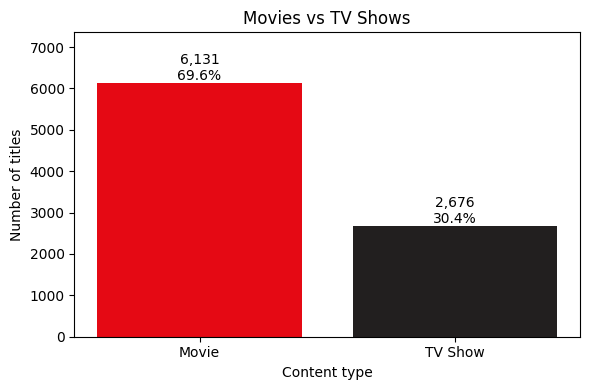

In [34]:
type_counts = df["type"].value_counts()
total_titles = int(type_counts.sum())

fig, ax = plt.subplots(figsize=(6, 4))
if type_counts.empty or total_titles == 0:
    ax.text(0.5, 0.5, "No data available", ha="center", va="center")
else:
    bars = ax.bar(type_counts.index, type_counts.values, color=["#e50914", "#221f1f"])
    ax.set_title("Movies vs TV Shows")
    ax.set_xlabel("Content type")
    ax.set_ylabel("Number of titles")
    for bar, count in zip(bars, type_counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, count,
                f"{count:,}\n{count / total_titles * 100:.1f}%",
                ha="center", va="bottom")
    ax.set_ylim(0, type_counts.max() * 1.2)
plt.tight_layout()
plt.show()

### Chart 2 — Number of Titles Added Each Year

Uses the date-valid dataset. A bar per year shows the steep climb to 2019 and
the slowdown afterwards.

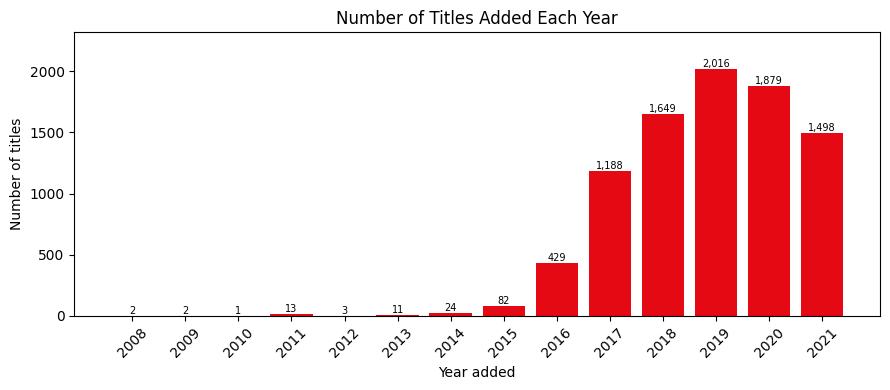

In [35]:
per_year = df_dated["year_added"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4))
if per_year.empty:
    ax.text(0.5, 0.5, "No data available", ha="center", va="center")
else:
    years = [int(year) for year in per_year.index]
    ax.bar(years, per_year.values, color="#e50914")
    ax.set_title("Number of Titles Added Each Year")
    ax.set_xlabel("Year added")
    ax.set_ylabel("Number of titles")
    ax.set_xticks(years)
    ax.tick_params(axis="x", rotation=45)
    for x, y in zip(years, per_year.values):
        ax.text(x, y, f"{int(y):,}", ha="center", va="bottom", fontsize=7)
    ax.set_ylim(0, per_year.max() * 1.15)
plt.tight_layout()
plt.show()

### Chart 3 — Top 10 Producing Countries

Horizontal bars keep the long country names readable. Counts come from the
exploded `country_rows` table, so co-productions are counted for every country.

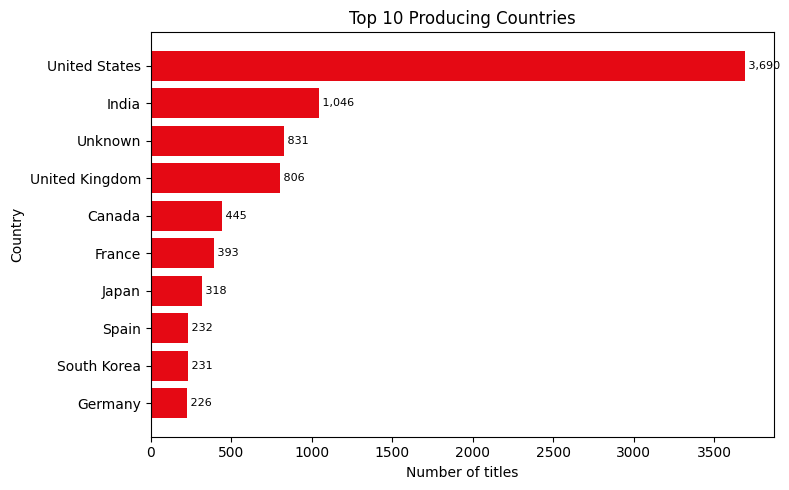

In [36]:
country_counts = country_rows["country"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(8, 5))
if country_counts.empty:
    ax.text(0.5, 0.5, "No data available", ha="center", va="center")
else:
    ax.barh(country_counts.index[::-1], country_counts.values[::-1], color="#e50914")
    ax.set_title("Top 10 Producing Countries")
    ax.set_xlabel("Number of titles")
    ax.set_ylabel("Country")
    for y, value in enumerate(country_counts.values[::-1]):
        ax.text(value, y, f" {int(value):,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

### Chart 4 — Top 5 Most Common Genres

Counts come from the exploded `genre_rows` table, so a title in several genres
counts once for each genre.

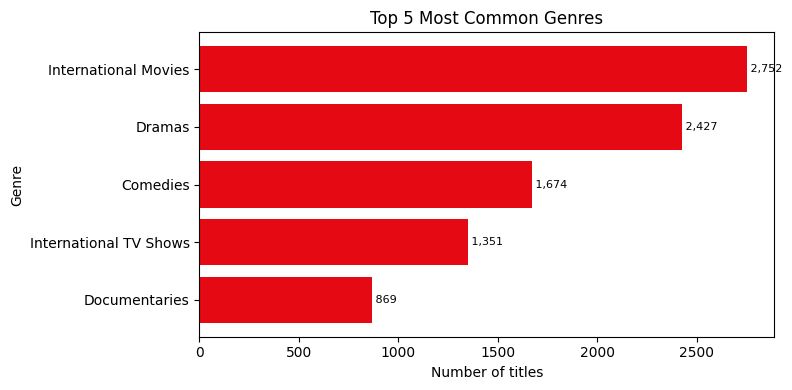

In [37]:
genre_counts = genre_rows["listed_in"].value_counts().head(5)

fig, ax = plt.subplots(figsize=(8, 4))
if genre_counts.empty:
    ax.text(0.5, 0.5, "No data available", ha="center", va="center")
else:
    ax.barh(genre_counts.index[::-1], genre_counts.values[::-1], color="#e50914")
    ax.set_title("Top 5 Most Common Genres")
    ax.set_xlabel("Number of titles")
    ax.set_ylabel("Genre")
    for y, value in enumerate(genre_counts.values[::-1]):
        ax.text(value, y, f" {int(value):,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

### Chart 5 — Rating Distribution

Every distinct rating is shown, most common first, so the adult skew (TV-MA,
TV-14) and the rare ratings are both visible. The three rows whose `rating`
holds a duration are visible as the small "66/74/84 min" bars, which is itself a
useful signal of a metadata defect.

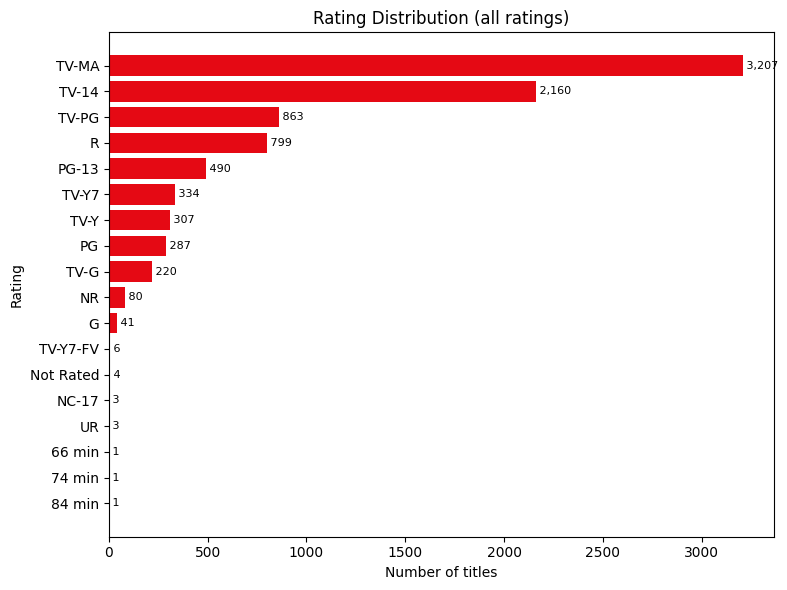

In [38]:
rating_counts = df["rating"].value_counts()

fig, ax = plt.subplots(figsize=(8, 6))
if rating_counts.empty:
    ax.text(0.5, 0.5, "No data available", ha="center", va="center")
else:
    ax.barh(rating_counts.index[::-1], rating_counts.values[::-1], color="#e50914")
    ax.set_title("Rating Distribution (all ratings)")
    ax.set_xlabel("Number of titles")
    ax.set_ylabel("Rating")
    for y, value in enumerate(rating_counts.values[::-1]):
        ax.text(value, y, f" {int(value):,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

### Chart 6 — Release-Year Distribution

A histogram of `release_year` in five-year bins shows how tightly the catalogue
is concentrated in recent decades, and makes the single 1925 outlier stand apart
from the main mass.

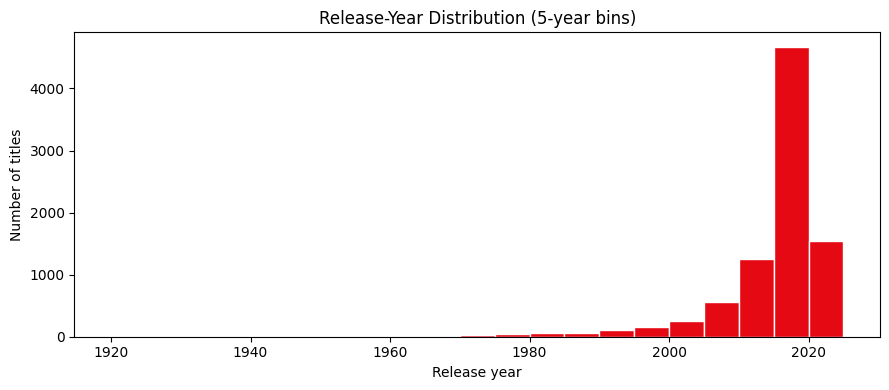

In [39]:
years = df["release_year"].dropna().astype(int)

fig, ax = plt.subplots(figsize=(9, 4))
if years.empty:
    ax.text(0.5, 0.5, "No data available", ha="center", va="center")
else:
    ax.hist(years, bins=range(1920, 2030, 5), color="#e50914", edgecolor="white")
    ax.set_title("Release-Year Distribution (5-year bins)")
    ax.set_xlabel("Release year")
    ax.set_ylabel("Number of titles")
plt.tight_layout()
plt.show()

## 13. Three Business Insights

The next cell prints the exact figures used in the three insights below, so the
statements are reproducible instead of guessed. All numbers come from the real
`data/netflix_titles.csv` and are reproduced in `README.md` and in
`output/sample_output.txt`.

In [40]:
print("=" * 70)
print("FIGURES SUPPORTING THE THREE BUSINESS INSIGHTS")
print("=" * 70)

type_counts = df["type"].value_counts()
total_titles = int(type_counts.sum())
print(f"\n1) Total titles (general dataset): {total_titles:,}")
print("   " + " | ".join(f"{name}: {int(count):,}" for name, count in type_counts.items()))
print("   " + " | ".join(f"{name}: {count / total_titles * 100:.1f}%"
                        for name, count in type_counts.items()))

print("\n2) Top 5 countries (after splitting multi-country cells):")
for rank, (country, count) in enumerate(country_rows["country"].value_counts().head(5).items(), start=1):
    print(f"   {rank}. {country:<28} {int(count):>5}")

print("\n3) Top 5 genres (after splitting listed_in):")
for rank, (genre, count) in enumerate(genre_rows["listed_in"].value_counts().head(5).items(), start=1):
    print(f"   {rank}. {genre:<28} {int(count):>5}")

print("\n4) Titles added per year (date-valid dataset), first and last 5 years:")
per_year = df_dated["year_added"].value_counts().sort_index()
for year in list(per_year.index)[:5] + list(per_year.index)[-5:]:
    print(f"   {int(year)}  {int(per_year.loc[year]):>5}")

print(f"\n   Peak year: {int(per_year.idxmax())} with {int(per_year.max()):,} titles")

named_countries = country_rows.loc[country_rows["country"] != "Unknown", "country"].nunique()
print(f"   Unique countries: {country_rows['country'].nunique()} "
      f"(named only: {named_countries})")

print("\n5) Rating distribution, top 5 ratings:")
for rank, (rating, count) in enumerate(df["rating"].value_counts().head(5).items(), start=1):
    print(f"   {rank}. {rating:<28} {int(count):>5}  ({count / total_titles * 100:.1f}%)")
print(f"   Unrated ('Not Rated'): {int((df['rating'] == 'Not Rated').sum()):,}")

years = df["release_year"].dropna().to_numpy(dtype=float)
print(f"\n6) Release year - mean {np.mean(years):.2f}, median {np.median(years):.0f}, "
      f"range {int(np.min(years))}-{int(np.max(years))}, std {np.std(years):.2f}")

FIGURES SUPPORTING THE THREE BUSINESS INSIGHTS

1) Total titles (general dataset): 8,807
   Movie: 6,131 | TV Show: 2,676
   Movie: 69.6% | TV Show: 30.4%

2) Top 5 countries (after splitting multi-country cells):
   1. United States                 3690
   2. India                         1046
   3. Unknown                        831
   4. United Kingdom                 806
   5. Canada                         445

3) Top 5 genres (after splitting listed_in):
   1. International Movies          2752
   2. Dramas                        2427
   3. Comedies                      1674
   4. International TV Shows        1351
   5. Documentaries                  869

4) Titles added per year (date-valid dataset), first and last 5 years:
   2008      2
   2009      2
   2010      1
   2011     13
   2012      3
   2017   1188
   2018   1649
   2019   2016
   2020   1879
   2021   1498

   Peak year: 2019 with 2,016 titles
   Unique countries: 123 (named only: 122)

5) Rating distribution, to

### The three insights

Every figure below comes from a run of this notebook on
`data/netflix_titles.csv` (8,807 raw rows; 8,797 with a usable date) and is
reproduced by the cell above. The same three paragraphs are in `README.md`.

**Insight 1 — A movie-led, recency-weighted library whose headline range is
misleading.** Movies dominate the catalogue at **6,131 titles (69.62%)** against
**2,676 TV Shows (30.38%)**. The NumPy statistics show what that catalogue is
made of: mean release year **2014.18**, median **2017**, and an interquartile
range of only **6 years** (Q1 2013, Q3 2019) — so the library is really a
2013–2019 collection. The advertised span of **1925–2021** is misleading: the
1925 minimum is a *single* title, *Pioneers: First Women Filmmakers\**. That one
row is why the mean sits 2.82 years below the median and why the standard
deviation (**8.82**) is larger than the IQR (6). For planning, the quartiles
describe the catalogue far better than the min/max range.

**Insight 2 — The catalogue scaled roughly 84× in five years, then cooled by
about 26%.** Additions went from **24 titles in 2014** to **429 (2016)**, **1,188
(2017)**, **1,649 (2018)** and a peak of **2,016 in 2019** — an 84-fold increase
— before falling to **1,879 (2020)** and **1,498 (2021)**, which is **25.69%**
below the peak. The mix also shifted: TV Shows were 29.4% of 2019 additions but
33.7% of 2021 additions, so the slowdown is concentrated in Movies (1,424 → 993)
rather than in series (592 → 505). Growth has clearly plateaued.

**Insight 3 — The library is international and adult-oriented, and some of its
metadata is not yet trustworthy.** The three largest genres are all broad,
mainstream categories — **International Movies (2,752)**, **Dramas (2,427)** and
**Comedies (1,674)** — and the audience skews adult: **TV-MA (3,207 / 36.41%)**
plus **TV-14 (2,160 / 24.53%)** make up **60.94%** of the catalogue, while
**G and PG together account for only 328 titles (3.72%)**. Geographically the
United States dominates with **3,690 titles**, **3.53×** India's 1,046, yet
**"Unknown" ranks third with 831 titles** because 9.44% of rows have no country
recorded. Three rows (`s5542`, `s5795`, `s5814` — the Louis C.K. specials) carry
a *duration* value ("74 min", "84 min", "66 min") in the `rating` column, which
is why the distribution shows 18 distinct ratings. Rating and country analytics
should therefore be cleaned at the source before they drive a decision.

## 14. Automated Tests

This section checks the analysis logic and the menu behaviour with a small,
made-up dataset, so most edge cases do **not** depend on the real CSV. The tests
use the standard-library `unittest` module, so no extra package is required. The
real dataset is only used for the handful of menu tests that check the on-screen
messages. Running the notebook top to bottom runs these tests automatically.

In [41]:
# --- A tiny, made-up dataset for the tests ---------------------------------
# It deliberately mixes single- and multi-value cells and includes missing
# values so the cleaning and splitting rules are all exercised.
TEST_COLUMNS = [
    "show_id", "type", "title", "director", "cast", "country",
    "date_added", "release_year", "rating", "listed_in",
]

TEST_ROWS = [
    {"show_id": "s1", "type": "Movie", "title": "Dark Sky",
     "director": "Ann", "cast": "Ava", "country": "United States, Canada",
     "date_added": "2015-01-01", "release_year": 2010, "rating": "PG",
     "listed_in": "Dramas, Comedies"},
    {"show_id": "s2", "type": "TV Show", "title": "Dark Water",
     "director": "Ben", "cast": "Bob", "country": "India",
     "date_added": "2019-06-01", "release_year": 2020, "rating": "TV-MA",
     "listed_in": "Dramas"},
    {"show_id": "s3", "type": "Movie", "title": "Bright Day",
     "director": pd.NA, "cast": pd.NA, "country": pd.NA,
     "date_added": pd.NA, "release_year": 2000, "rating": pd.NA,
     "listed_in": "Comedies"},
]


def make_test_frame(rows):
    """Build a small raw-style DataFrame for the tests."""
    return pd.DataFrame(rows, columns=TEST_COLUMNS)


TEST_RAW = make_test_frame(TEST_ROWS)
TEST_CLEAN, TEST_DETAILS = clean_dataframe(TEST_RAW)
TEST_DATED = TEST_CLEAN[TEST_CLEAN["date_added"].notna()].copy()
TEST_COUNTRY_ROWS = explode_multi_value(TEST_CLEAN, "country")
TEST_GENRE_ROWS = explode_multi_value(TEST_CLEAN, "listed_in")


class TestCleaning(unittest.TestCase):
    def test_missing_text_is_filled(self):
        self.assertEqual(TEST_CLEAN["country"].isna().sum(), 0)
        row = TEST_CLEAN.loc[TEST_CLEAN["show_id"] == "s3"].iloc[0]
        self.assertEqual(row["country"], "Unknown")
        self.assertEqual(row["director"], "Not Listed")
        self.assertEqual(row["cast"], "Not Listed")
        self.assertEqual(row["rating"], "Not Rated")

    def test_cleaning_details(self):
        self.assertEqual(TEST_DETAILS["filled"]["country"], 1)
        self.assertEqual(TEST_DETAILS["unparsed_dates"], 1)

    def test_dates_and_year_added(self):
        self.assertTrue(str(TEST_CLEAN["date_added"].dtype).startswith("datetime64"))
        row = TEST_CLEAN.loc[TEST_CLEAN["show_id"] == "s2"].iloc[0]
        self.assertEqual(int(row["year_added"]), 2019)
        self.assertEqual(len(TEST_DATED), 2)

    def test_missing_dataset_raises(self):
        with self.assertRaises(FileNotFoundError):
            load_dataset("definitely_missing_file.csv", path=None)


class TestAnalysisLogic(unittest.TestCase):
    def test_movies_vs_tvshows(self):
        table = count_movies_tvshows(TEST_CLEAN)
        counts = dict(zip(table["Content Type"], table["Count"]))
        self.assertEqual(counts["Movie"], 2)
        self.assertEqual(counts["TV Show"], 1)

    def test_titles_added_each_year(self):
        per_year = titles_added_each_year(TEST_DATED)
        self.assertEqual(sorted(per_year.index.tolist()), [2015, 2019])
        self.assertEqual(int(per_year.loc[2015]), 1)
        self.assertEqual(int(per_year.loc[2019]), 1)

    def test_countries_split_and_counted(self):
        counts = top_countries(10, TEST_COUNTRY_ROWS)
        self.assertEqual(int(counts["United States"]), 1)
        self.assertEqual(int(counts["Canada"]), 1)
        self.assertEqual(int(counts["India"]), 1)
        self.assertEqual(int(counts["Unknown"]), 1)

    def test_genres_split_and_counted(self):
        counts = top_genres(5, TEST_GENRE_ROWS)
        self.assertEqual(int(counts["Dramas"]), 2)
        self.assertEqual(int(counts["Comedies"]), 2)

    def test_rating_distribution(self):
        counts = rating_distribution(TEST_CLEAN)
        self.assertEqual(int(counts["PG"]), 1)
        self.assertEqual(int(counts["TV-MA"]), 1)
        self.assertEqual(int(counts["Not Rated"]), 1)

    def test_release_year_range(self):
        result = release_year_range(TEST_CLEAN)
        self.assertEqual(result["oldest"], 2000)
        self.assertEqual(result["newest"], 2020)

    def test_search_is_case_insensitive(self):
        matches = search_titles(TEST_CLEAN, "dark")
        self.assertEqual(len(matches), 2)

    def test_search_no_match(self):
        matches = search_titles(TEST_CLEAN, "nothing-matches-this")
        self.assertTrue(matches.empty)

    def test_search_empty_keyword(self):
        self.assertIsNone(search_titles(TEST_CLEAN, ""))

    def test_content_added_in_year(self):
        subset = content_added_in_year(TEST_DATED, 2019)
        self.assertEqual(len(subset), 1)
        self.assertEqual(subset["Title"].iloc[0], "Dark Water")

    def test_content_added_empty_year(self):
        subset = content_added_in_year(TEST_DATED, 1990)
        self.assertTrue(subset.empty)

    def test_unique_countries_excludes_unknown(self):
        result = unique_countries(TEST_COUNTRY_ROWS)
        self.assertEqual(result["total"], 4)   # United States, Canada, India, Unknown
        self.assertEqual(result["named"], 3)   # United States, Canada, India

    def test_release_year_statistics(self):
        stats = release_year_statistics(TEST_CLEAN)
        self.assertEqual(stats["count"], 3)
        self.assertAlmostEqual(stats["mean"], (2010 + 2020 + 2000) / 3)
        self.assertEqual(stats["min"], 2000)
        self.assertEqual(stats["max"], 2020)


class TestEdgeCases(unittest.TestCase):
    def test_empty_data_does_not_crash(self):
        empty = clean_dataframe(make_test_frame([]))[0]
        empty_countries = explode_multi_value(empty, "country")
        self.assertTrue(count_movies_tvshows(empty).empty)
        self.assertTrue(rating_distribution(empty).empty)
        self.assertEqual(release_year_range(empty), {})
        self.assertEqual(release_year_statistics(empty), {})
        self.assertTrue(top_countries(10, empty_countries).empty)
        self.assertTrue(titles_added_each_year(empty).empty)


class TestMenuBehaviour(unittest.TestCase):
    def test_quit(self):
        self.assertIn("Goodbye", run_scripted_session(["0"]))

    def test_invalid_menu_choice(self):
        self.assertIn("Invalid choice", run_scripted_session(["99", "0"]))

    def test_non_numeric_year_is_rejected(self):
        self.assertIn("Invalid year", run_scripted_session(["8", "abc", "2019", "0"]))

    def test_out_of_range_year_is_rejected(self):
        self.assertIn("between 1900", run_scripted_session(["8", "1800", "", "0"]))

    def test_empty_keyword_message(self):
        self.assertIn("Nothing to search for", run_scripted_session(["7", "", "0"]))

    def test_no_match_message(self):
        self.assertIn("No titles found", run_scripted_session(["7", "zzzznope", "0"]))

In [42]:
def run_notebook_tests():
    """Run every test class and print a short summary."""
    loader = unittest.TestLoader()
    suite = unittest.TestSuite()
    for case in (TestCleaning, TestAnalysisLogic, TestEdgeCases, TestMenuBehaviour):
        suite.addTests(loader.loadTestsFromTestCase(case))

    stream = io.StringIO()
    result = unittest.TextTestRunner(stream=stream, verbosity=2).run(suite)
    print(stream.getvalue())
    print("=" * 70)
    print(f"Tests run : {result.testsRun}")
    print(f"Failures  : {len(result.failures)}")
    print(f"Errors    : {len(result.errors)}")
    print("ALL TESTS PASSED" if result.wasSuccessful() else "SOME TESTS FAILED - see above")
    return result


test_result = run_notebook_tests()


CONTENT ADDED IN A SPECIFIC YEAR

No content found for that year.
Years that contain content: 2015 - 2019

CONTENT ADDED IN A SPECIFIC YEAR

1 title(s) added in 2019:
--------------------------------------------------
     Title    Type  Release Year Rating Date Added
Dark Water TV Show          2020  TV-MA 2019-06-01

TOP 10 PRODUCING COUNTRIES
 Rank       Country  Number of Titles
    1 United States                 1
    2        Canada                 1
    3         India                 1
    4       Unknown                 1

Note: a title produced in several countries is counted once for each
country, so these numbers add up to more than the 8,807 titles in
the catalogue. Rows with no country listed appear as 'Unknown'.

TOP 5 MOST COMMON GENRES
 Rank    Genre  Number of Titles
    1   Dramas                 2
    2 Comedies                 2

Note: one title can belong to several genres, so the genre counts
add up to more than the 8,807 titles in the catalogue.

MOVIES VS TV 

## 15. Conclusion

This project delivers a complete, self-contained data-analysis application for
the Netflix Titles Dataset:

* **Loaded** 8,807 rows from `data/netflix_titles.csv` with Pandas, using a
  search that works no matter which folder Jupyter was started from, and a
  clear error message when the file is missing.
* **Explored** the raw data — shape, dtypes, head/tail, `info()`, a
  missing-value profile and a duplicate check.
* **Cleaned** the data: `country` → `"Unknown"`, `director` and `cast` →
  `"Not Listed"`, `rating` → `"Not Rated"`, `date_added` parsed into real
  datetimes, and `year_added` derived. A PASS/FAIL validation table proves every
  cleaning rule held.
* **Kept two views** — a general dataset (`df`, all rows) for analyses that do
  not need a date, and a date-valid dataset (`df_dated`) for options 2 and 8 —
  so the 10 titles without a `date_added` are not lost to unrelated questions.
* **Engineered** features — numeric `release_year`, `release_decade`,
  `duration_minutes`, and exploded long-format country and genre tables so that
  multi-value cells are counted correctly.
* **Analysed** the catalogue through ten documented, menu-driven functions that
  combine Pandas for counting with NumPy for the numerical statistics.
* **Visualised** the six key results with Matplotlib (section 12).
* **Validated** the result with an automated `unittest` suite (section 14) and a
  reproducible sample run of every option, saved to `output/sample_output.txt`.

### What was learned

1. Data cleaning is not optional. **3,472 rows (39.42%)** were missing at least
   one of `country`, `director`, `cast` or `rating`, and 10 rows have no
   `date_added` at all — which is why the analyses that need a date use a
   separate, smaller view.
2. Multi-value cells are a silent source of wrong answers. Splitting
   `"United States, Canada"` and `"Dramas, International Movies"` before
   counting is what turns `df["country"].nunique()` (which would merge
   co-productions into one meaningless label) into a usable 123 countries.
3. One function per question is the simplest way to keep a growing analysis
   readable — and it is what makes a menu possible at all.
4. Summary statistics need their outliers checked. The 1925 minimum is a single
   title, which is why the standard deviation (8.82) exceeds the interquartile
   range (6) and the mean (2014.18) sits below the median (2017).
5. Real datasets carry real defects. Three rows have a duration value in the
   `rating` column, and 831 rows have no country at all — both visible only
   because the analysis reports every distinct value instead of a hand-picked
   list.

### Possible extensions

* Save the cleaned table to `output/netflix_cleaned.csv` for further work.
* Cross-tabulate genre against content type to compare Movies with TV Shows.
* Add a keyword search across `cast` and `director` as well as `title`.

### Reproducing the sample output

Run the notebook top to bottom with the real dataset in `data/`. Section 11
feeds a scripted list of answers into `main()` and writes the captured console
text to `output/sample_output.txt`, and the "Three Business Insights" section
prints the exact figures the written insights must match.